In [1]:
import wandb
import sys
import matplotlib.pyplot as plt
import scprep
import pandas as pd
sys.path.append('../hypgs/models')
from omegaconf import OmegaConf
from train_ae import load_data, make_model
import numpy as np
import os
import glob
import scanpy as sc
os.chdir('/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/hypergraph_scattering/hypgs/models')

In [2]:
# Initialize wandb (replace 'your_entity' and 'your_project' with your specific details)
wandb.login()
api = wandb.Api()

# Specify your entity, project, and sweep ID
entity = "xingzhis"
project = "dmae"
sweep_id = 'pum5oq2t'

# Fetch the sweep
sweep = api.sweep(f"{entity}/{project}/{sweep_id}")

run_ids = [run.id for run in sweep.runs]
# run_id = 'whgqtghz'
# run = [run for run in sweep.runs if run.id == run_id][0]

# cfg = OmegaConf.create(run.config)
folder_path = "wandb/"
# folder_list = glob.glob(f"{folder_path}*{run.id}*")
# ckpt_files = glob.glob(f"{folder_list[0]}/files/*.ckpt")
# ckpt_path = ckpt_files[0]
# allloader, _, X, phate_coords, colors, dist, pp = load_data(cfg, load_all=True)
# emb_dim = phate_coords.shape[1]
# data_path = os.path.join(cfg.data.root, cfg.data.name + cfg.data.filetype)
# data = np.load(data_path, allow_pickle=True)
# dist_std = np.std(data['dist'].flatten())
# model = make_model(cfg, X.shape[1], emb_dim, pp, dist_std, from_checkpoint=True, checkpoint_path=ckpt_path)
# model.eval()
# x_all = next(iter(allloader))['x']
# x_pred, z_pred = model(x_all)
# x_pred = x_pred.detach().cpu().numpy()
# z_pred = z_pred.detach().cpu().numpy()

# os.chdir("../../notebooks")

Failed to detect the name of this notebook, you can set it manually with the WANDB_NOTEBOOK_NAME environment variable to enable code saving.
wandb: Currently logged in as: xingzhis. Use `wandb login --relogin` to force relogin


In [13]:
import torch
run = [run for run in sweep.runs if run.id == 'bae5whsi'][0]
cfg = OmegaConf.create(run.config)
folder_path = "wandb/"
folder_list = glob.glob(f"{folder_path}*{run.id}*")
ckpt_files = glob.glob(f"{folder_list[0]}/files/*.ckpt")
ckpt_path = ckpt_files[0]
trainloader, valloader, X, phate_coords, colors, dist = load_data(cfg)
emb_dim = phate_coords.shape[1]
data_path = os.path.join(cfg.data.root, cfg.data.name + cfg.data.filetype)
data = np.load(data_path, allow_pickle=True)
dist_std = np.std(data['dist'].flatten())
model = make_model(cfg, X.shape[1], emb_dim, dist_std, from_checkpoint=True, checkpoint_path=ckpt_path)
model.eval()
x_all = torch.tensor(data['data'][data['is_train']]).float()
x_pred, z_pred = model(x_all)
x_pred = x_pred.detach().cpu().numpy()
z_pred = z_pred.detach().cpu().numpy()
experiment = 'contrastive+reconstruction'

In [4]:
classes = np.load('../../data/merfish_hyperedge_class.npy', allow_pickle=True)
classes = classes[data['is_train']]

/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/geosink/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


<Axes: title={'center': 'contrastive+reconstruction'}>

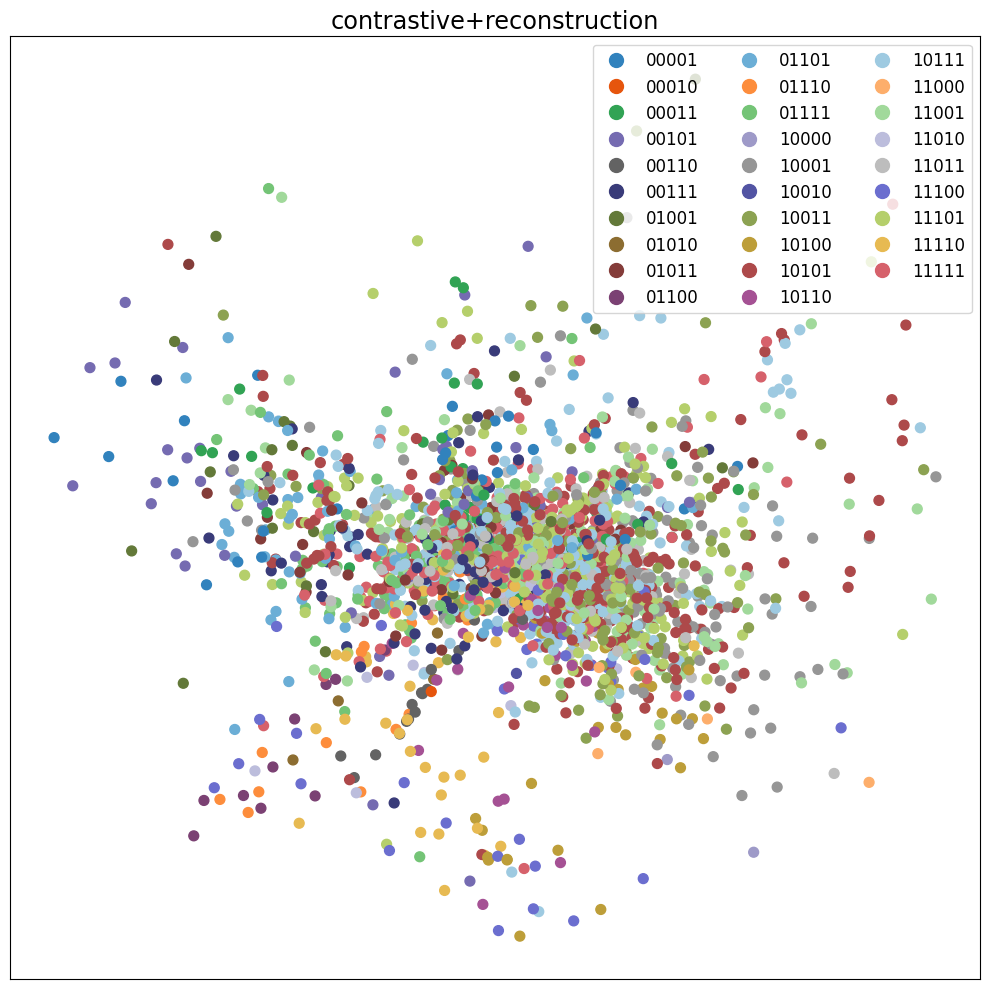

In [15]:
scprep.plot.scatter2d(z_pred, title=experiment, ticks=False,c=classes, figsize=(10,10), s=50)

/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/geosink/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


<Axes: title={'center': 'reconstruction only'}>

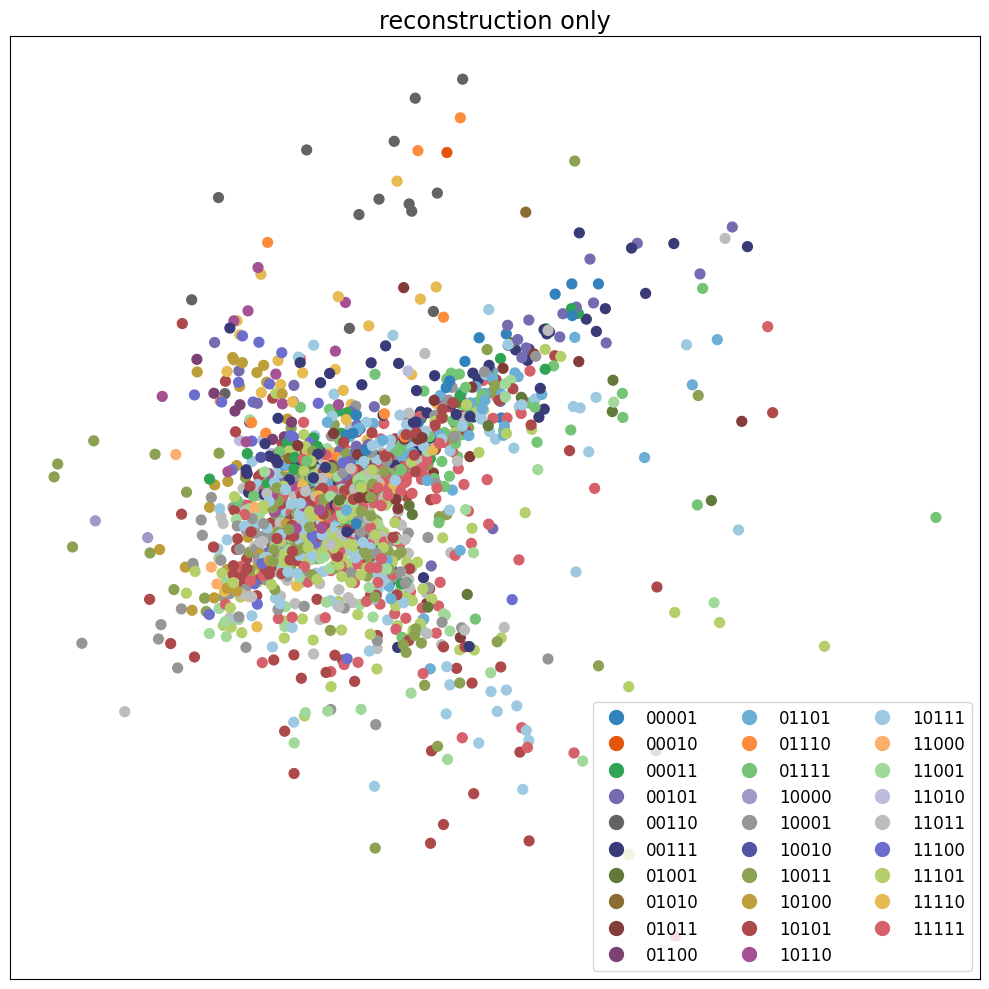

In [16]:
import torch
run = [run for run in sweep.runs if run.id == 'xit1j75h'][0]
cfg = OmegaConf.create(run.config)
folder_path = "wandb/"
folder_list = glob.glob(f"{folder_path}*{run.id}*")
ckpt_files = glob.glob(f"{folder_list[0]}/files/*.ckpt")
ckpt_path = ckpt_files[0]
trainloader, valloader, X, phate_coords, colors, dist = load_data(cfg)
emb_dim = phate_coords.shape[1]
data_path = os.path.join(cfg.data.root, cfg.data.name + cfg.data.filetype)
data = np.load(data_path, allow_pickle=True)
dist_std = np.std(data['dist'].flatten())
model = make_model(cfg, X.shape[1], emb_dim, dist_std, from_checkpoint=True, checkpoint_path=ckpt_path)
model.eval()
x_all = torch.tensor(data['data'][data['is_train']]).float()
x_pred, z_pred = model(x_all)
x_pred = x_pred.detach().cpu().numpy()
z_pred = z_pred.detach().cpu().numpy()
experiment = 'reconstruction only'

scprep.plot.scatter2d(z_pred, title=experiment, ticks=False,c=classes, figsize=(10,10), s=50)

/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/geosink/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


<Axes: title={'center': 'contrastive+phate+reconstruction'}>

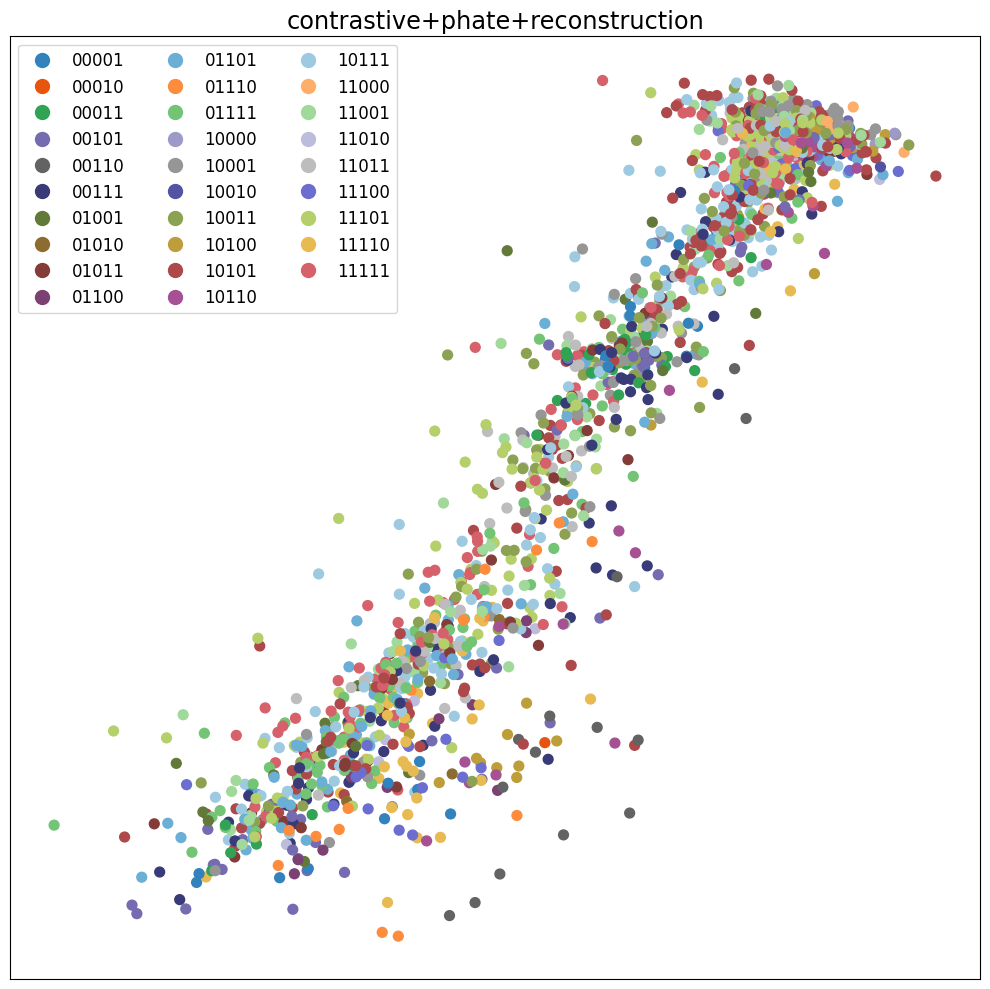

In [17]:
import torch
run = [run for run in sweep.runs if run.id == 'yja8hajr'][0]
cfg = OmegaConf.create(run.config)
folder_path = "wandb/"
folder_list = glob.glob(f"{folder_path}*{run.id}*")
ckpt_files = glob.glob(f"{folder_list[0]}/files/*.ckpt")
ckpt_path = ckpt_files[0]
trainloader, valloader, X, phate_coords, colors, dist = load_data(cfg)
emb_dim = phate_coords.shape[1]
data_path = os.path.join(cfg.data.root, cfg.data.name + cfg.data.filetype)
data = np.load(data_path, allow_pickle=True)
dist_std = np.std(data['dist'].flatten())
model = make_model(cfg, X.shape[1], emb_dim, dist_std, from_checkpoint=True, checkpoint_path=ckpt_path)
model.eval()
x_all = torch.tensor(data['data'][data['is_train']]).float()
x_pred, z_pred = model(x_all)
x_pred = x_pred.detach().cpu().numpy()
z_pred = z_pred.detach().cpu().numpy()
experiment = 'contrastive+phate+reconstruction'

scprep.plot.scatter2d(z_pred, title=experiment, ticks=False,c=classes, figsize=(10,10), s=50)

/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/geosink/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


<Axes: title={'center': 'bitwise contrastive+reconstruction'}>

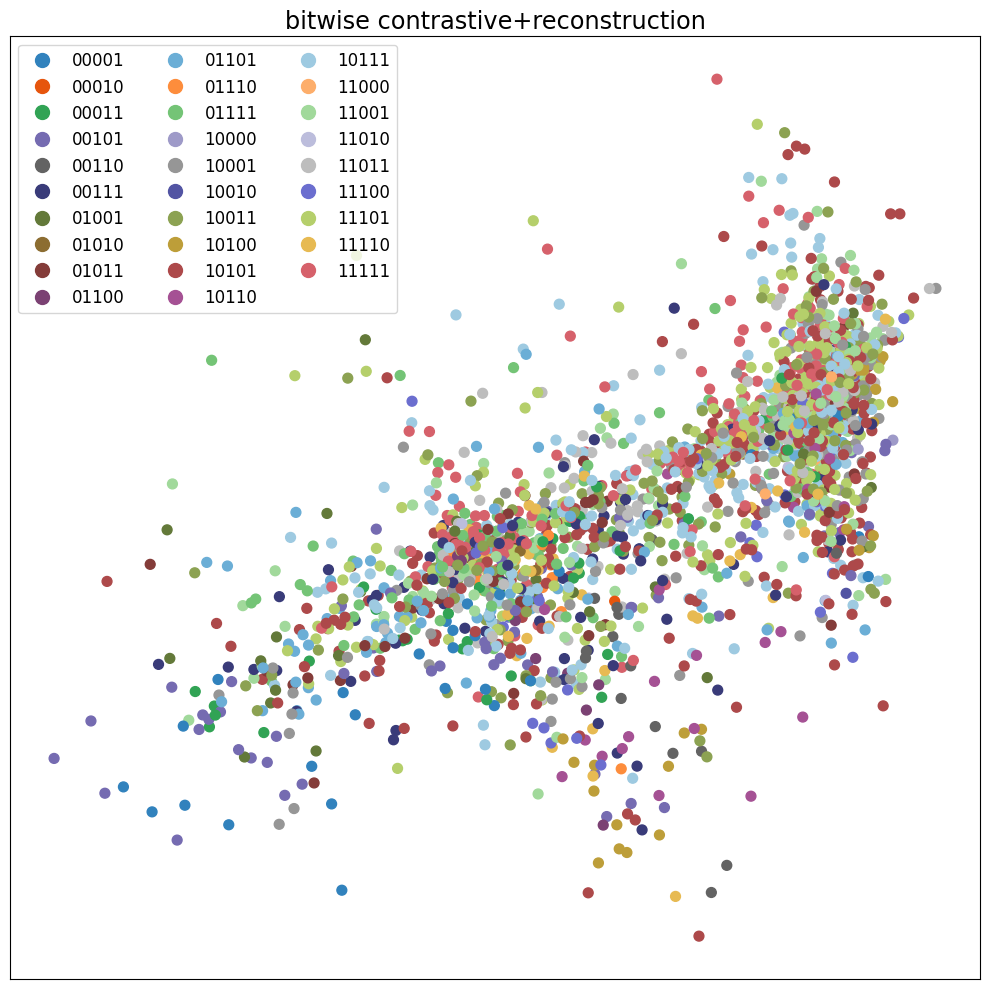

In [6]:
import torch
run = [run for run in sweep.runs if run.id == 'tzy2cjkx'][0]
cfg = OmegaConf.create(run.config)
folder_path = "wandb/"
folder_list = glob.glob(f"{folder_path}*{run.id}*")
ckpt_files = glob.glob(f"{folder_list[0]}/files/*.ckpt")
ckpt_path = ckpt_files[0]
trainloader, valloader, X, phate_coords, colors, dist = load_data(cfg)
emb_dim = phate_coords.shape[1]
data_path = os.path.join(cfg.data.root, cfg.data.name + cfg.data.filetype)
data = np.load(data_path, allow_pickle=True)
dist_std = np.std(data['dist'].flatten())
model = make_model(cfg, X.shape[1], emb_dim, dist_std, from_checkpoint=True, checkpoint_path=ckpt_path)
model.eval()
x_all = torch.tensor(data['data'][data['is_train']]).float()
x_pred, z_pred = model(x_all)
x_pred = x_pred.detach().cpu().numpy()
z_pred = z_pred.detach().cpu().numpy()
experiment = 'bitwise contrastive+reconstruction'

scprep.plot.scatter2d(z_pred, title=experiment, ticks=False,c=classes, figsize=(10,10), s=50)

/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/geosink/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


<Axes: title={'center': 'contrastive+reconstruction+hamming dist'}>

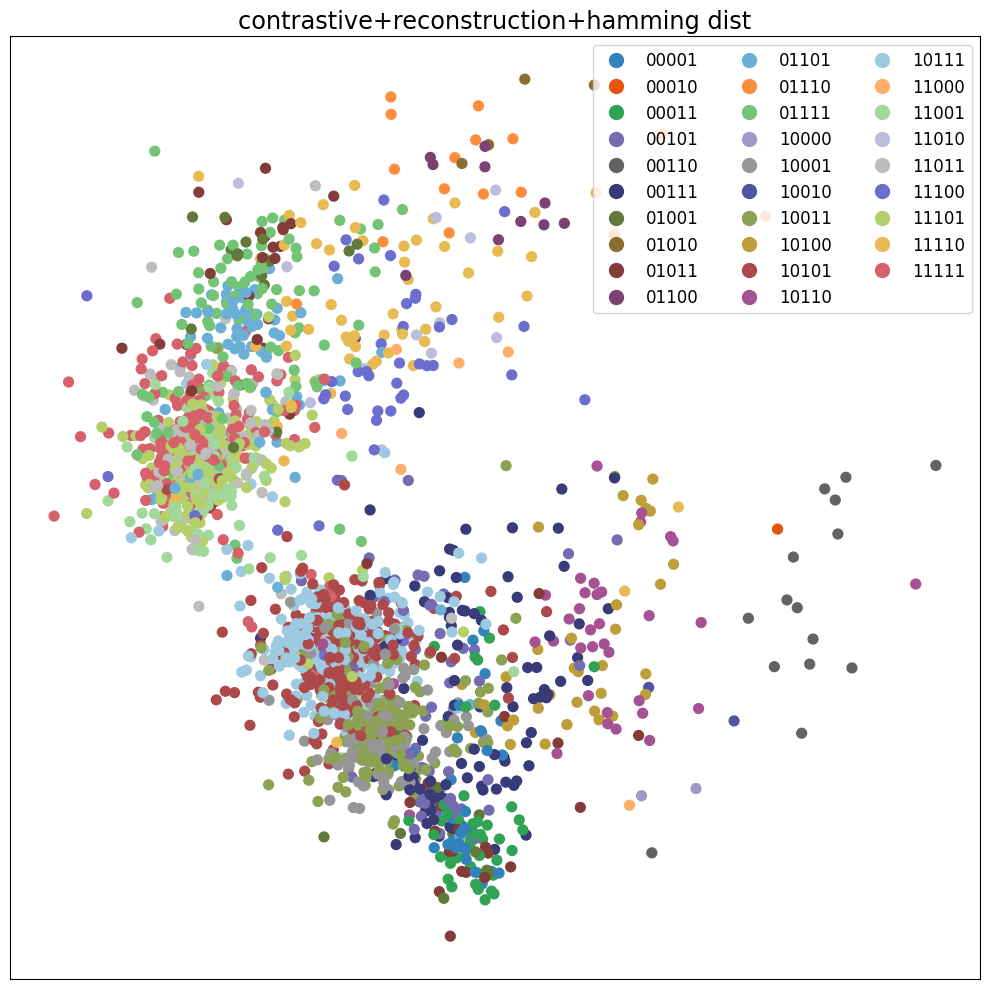

In [19]:
import torch
run = [run for run in sweep.runs if run.id == '2m7dqvdb'][0]
cfg = OmegaConf.create(run.config)
folder_path = "wandb/"
folder_list = glob.glob(f"{folder_path}*{run.id}*")
ckpt_files = glob.glob(f"{folder_list[0]}/files/*.ckpt")
ckpt_path = ckpt_files[0]
trainloader, valloader, X, phate_coords, colors, dist = load_data(cfg)
emb_dim = phate_coords.shape[1]
data_path = os.path.join(cfg.data.root, cfg.data.name + cfg.data.filetype)
data = np.load(data_path, allow_pickle=True)
dist_std = np.std(data['dist'].flatten())
model = make_model(cfg, X.shape[1], emb_dim, dist_std, from_checkpoint=True, checkpoint_path=ckpt_path)
model.eval()
x_all = torch.tensor(data['data'][data['is_train']]).float()
x_pred, z_pred = model(x_all)
x_pred = x_pred.detach().cpu().numpy()
z_pred = z_pred.detach().cpu().numpy()
experiment = 'contrastive+reconstruction+hamming dist'

scprep.plot.scatter2d(z_pred, title=experiment, ticks=False,c=classes, figsize=(10,10), s=50)

/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/geosink/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


<Axes: title={'center': 'reconstruction+hamming dist'}>

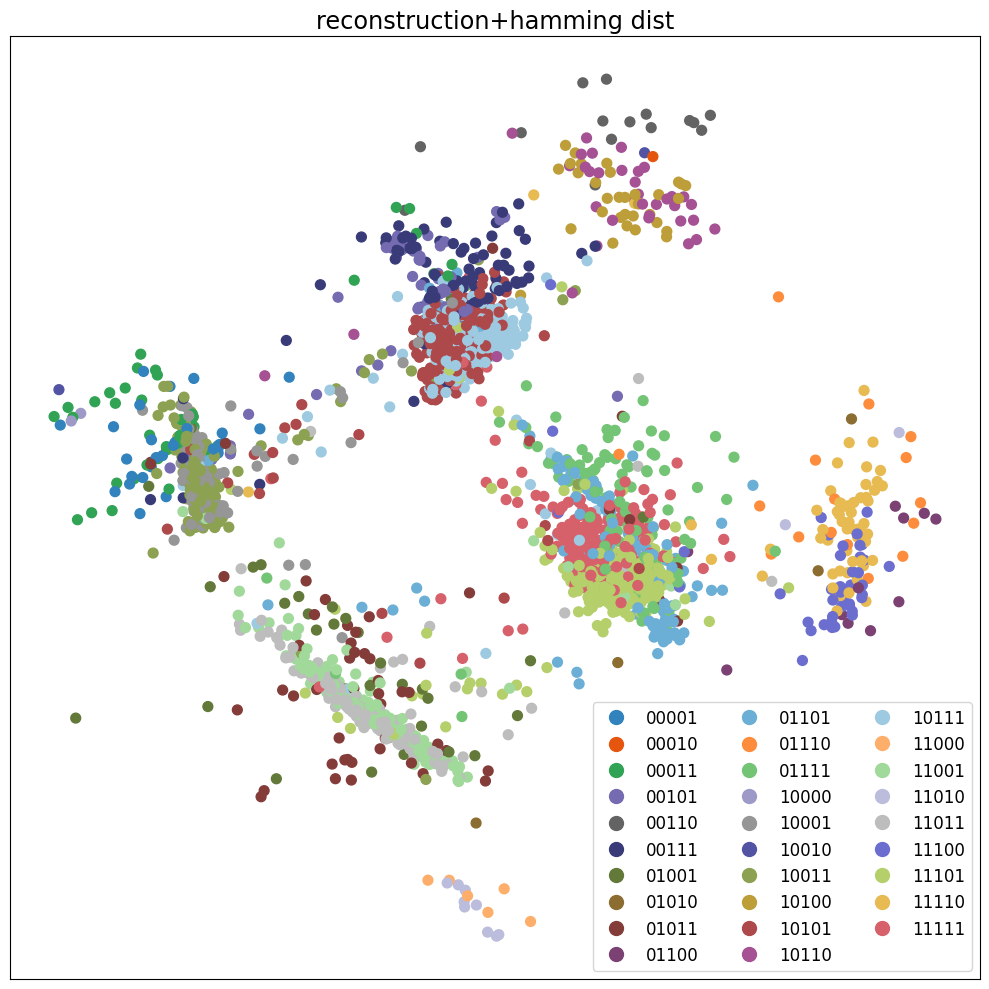

In [20]:
import torch
run = [run for run in sweep.runs if run.id == '5rt1n5y0'][0]
cfg = OmegaConf.create(run.config)
folder_path = "wandb/"
folder_list = glob.glob(f"{folder_path}*{run.id}*")
ckpt_files = glob.glob(f"{folder_list[0]}/files/*.ckpt")
ckpt_path = ckpt_files[0]
trainloader, valloader, X, phate_coords, colors, dist = load_data(cfg)
emb_dim = phate_coords.shape[1]
data_path = os.path.join(cfg.data.root, cfg.data.name + cfg.data.filetype)
data = np.load(data_path, allow_pickle=True)
dist_std = np.std(data['dist'].flatten())
model = make_model(cfg, X.shape[1], emb_dim, dist_std, from_checkpoint=True, checkpoint_path=ckpt_path)
model.eval()
x_all = torch.tensor(data['data'][data['is_train']]).float()
x_pred, z_pred = model(x_all)
x_pred = x_pred.detach().cpu().numpy()
z_pred = z_pred.detach().cpu().numpy()
experiment = 'reconstruction+hamming dist'

scprep.plot.scatter2d(z_pred, title=experiment, ticks=False,c=classes, figsize=(10,10), s=50)

/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/geosink/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


<Axes: title={'center': 'reconstruction+log dist'}>

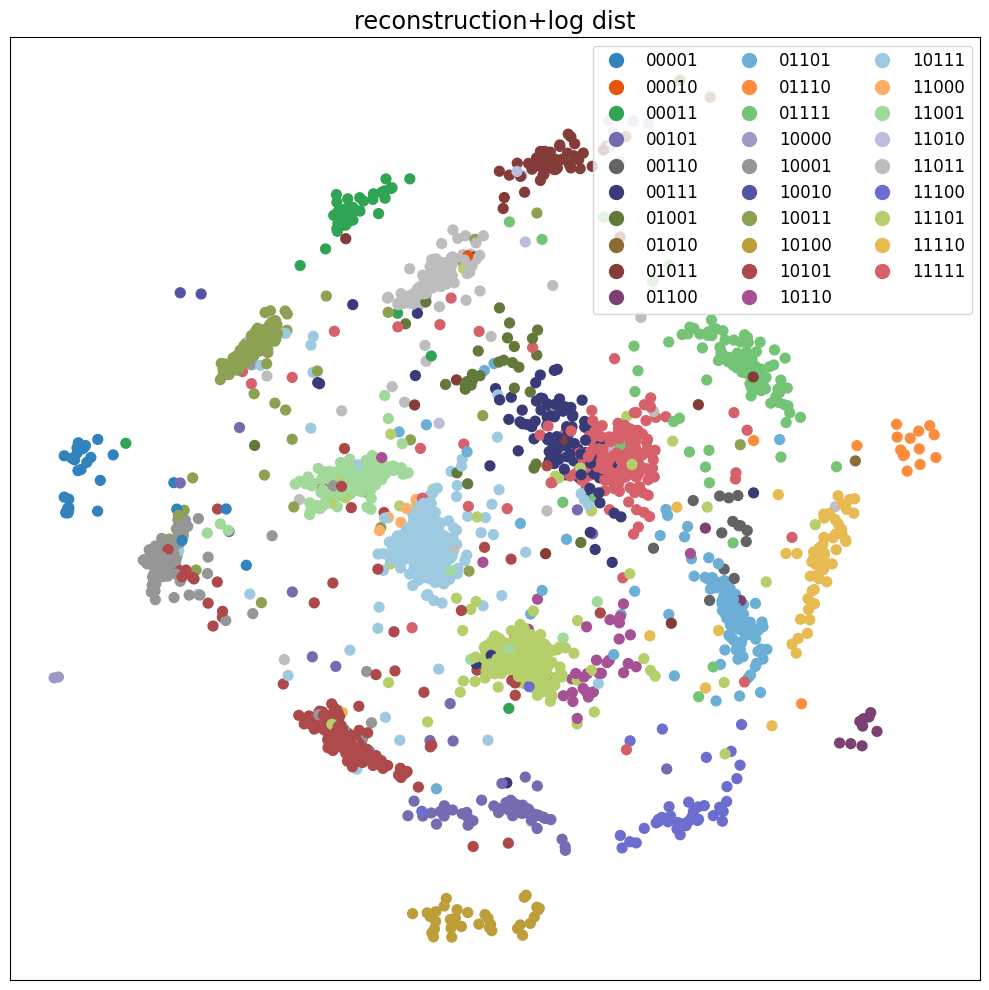

In [22]:
import torch
run = [run for run in sweep.runs if run.id == 'b2u2rpv5'][0]
cfg = OmegaConf.create(run.config)
folder_path = "wandb/"
folder_list = glob.glob(f"{folder_path}*{run.id}*")
ckpt_files = glob.glob(f"{folder_list[0]}/files/*.ckpt")
ckpt_path = ckpt_files[0]
trainloader, valloader, X, phate_coords, colors, dist = load_data(cfg)
emb_dim = phate_coords.shape[1]
data_path = os.path.join(cfg.data.root, cfg.data.name + cfg.data.filetype)
data = np.load(data_path, allow_pickle=True)
dist_std = np.std(data['dist'].flatten())
model = make_model(cfg, X.shape[1], emb_dim, dist_std, from_checkpoint=True, checkpoint_path=ckpt_path)
model.eval()
x_all = torch.tensor(data['data'][data['is_train']]).float()
x_pred, z_pred = model(x_all)
x_pred = x_pred.detach().cpu().numpy()
z_pred = z_pred.detach().cpu().numpy()
experiment = 'reconstruction+log dist'

scprep.plot.scatter2d(z_pred, title=experiment, ticks=False,c=classes, figsize=(10,10), s=50)

/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/geosink/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


<Axes: title={'center': 'reconstruction+contrastive+log dist'}>

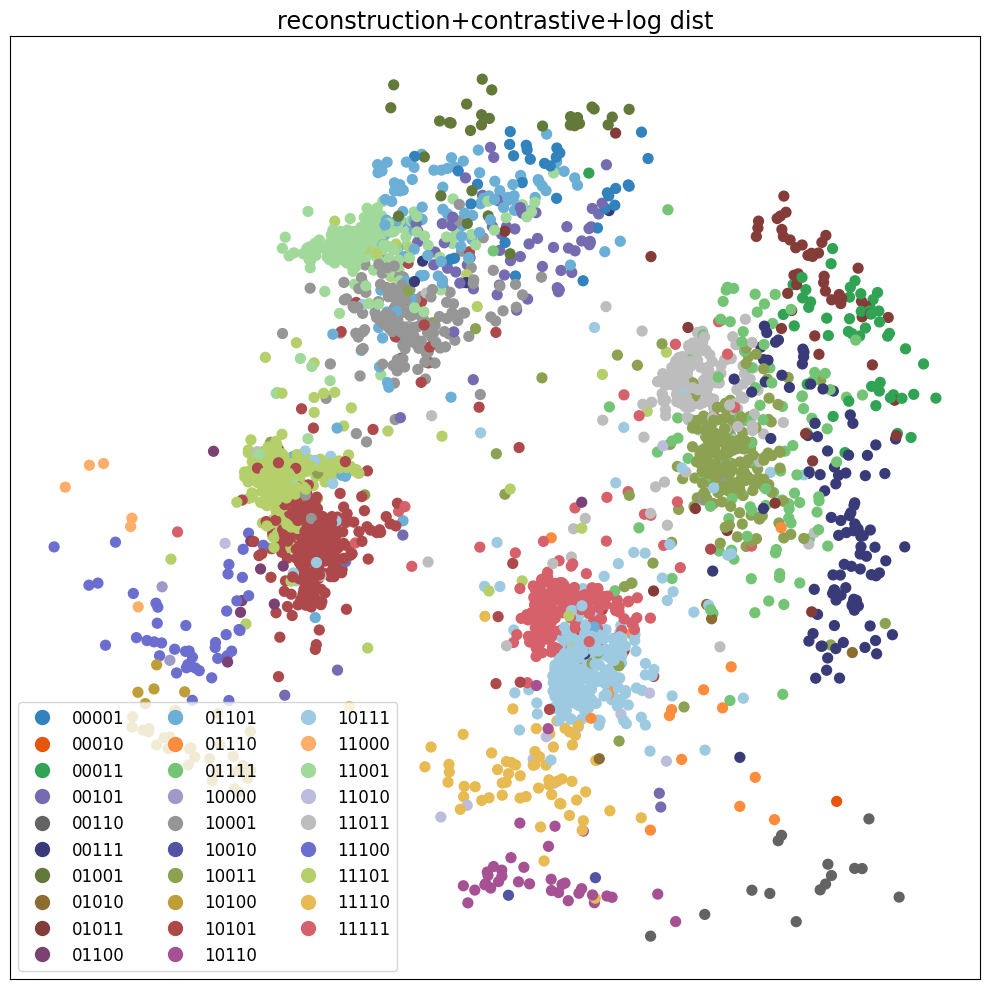

In [5]:
import torch
run = [run for run in sweep.runs if run.id == 'rsf6lvs5'][0]
cfg = OmegaConf.create(run.config)
folder_path = "wandb/"
folder_list = glob.glob(f"{folder_path}*{run.id}*")
ckpt_files = glob.glob(f"{folder_list[0]}/files/*.ckpt")
ckpt_path = ckpt_files[0]
trainloader, valloader, X, phate_coords, colors, dist = load_data(cfg)
emb_dim = phate_coords.shape[1]
data_path = os.path.join(cfg.data.root, cfg.data.name + cfg.data.filetype)
data = np.load(data_path, allow_pickle=True)
dist_std = np.std(data['dist'].flatten())
model = make_model(cfg, X.shape[1], emb_dim, dist_std, from_checkpoint=True, checkpoint_path=ckpt_path)
model.eval()
x_all = torch.tensor(data['data'][data['is_train']]).float()
x_pred, z_pred = model(x_all)
x_pred = x_pred.detach().cpu().numpy()
z_pred = z_pred.detach().cpu().numpy()
experiment = 'reconstruction+contrastive+log dist'

scprep.plot.scatter2d(z_pred, title=experiment, ticks=False,c=classes, figsize=(10,10), s=50)

In [21]:
assert False
# np.save('ae_embedding.npy', z_pred)

AssertionError: 

In [ ]:
os.chdir("../dmae/notebooks/")

# Initialize wandb (replace 'your_entity' and 'your_project' with your specific details)
wandb.login()
api = wandb.Api()

# Specify your entity, project, and sweep ID
entity = "xingzhis"
project = "dmae"
sweep_id = 'co8e8y4e'

# Fetch the sweep
sweep = api.sweep(f"{entity}/{project}/{sweep_id}")

run_ids = [run.id for run in sweep.runs]
run_id = 'xpoewpyd'
run = [run for run in sweep.runs if run.id == run_id][0]

cfg = OmegaConf.create(run.config)
folder_path = "../src/wandb/"
folder_list = glob.glob(f"{folder_path}*{run.id}*")
ckpt_files = glob.glob(f"{folder_list[0]}/files/*.ckpt")
ckpt_path = ckpt_files[0]
allloader, _, X, phate_coords, colors, dist, pp = load_data(cfg, load_all=True)
emb_dim = phate_coords.shape[1]
data_path = os.path.join(cfg.data.root, cfg.data.name + cfg.data.filetype)
data = np.load(data_path, allow_pickle=True)
dist_std = np.std(data['dist'].flatten())
model = make_model(cfg, X.shape[1], emb_dim, pp, dist_std, from_checkpoint=True, checkpoint_path=ckpt_path)
model.eval()
x_all = next(iter(allloader))['x']
x_pred, z_pred = model(x_all)
x_pred = x_pred.detach().cpu().numpy()
z_pred = z_pred.detach().cpu().numpy()

os.chdir("../../notebooks")

Failed to detect the name of this notebook, you can set it manually with the WANDB_NOTEBOOK_NAME environment variable to enable code saving.
wandb: Currently logged in as: xingzhis. Use `wandb login --relogin` to force relogin


/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/geosink/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


<Axes: >

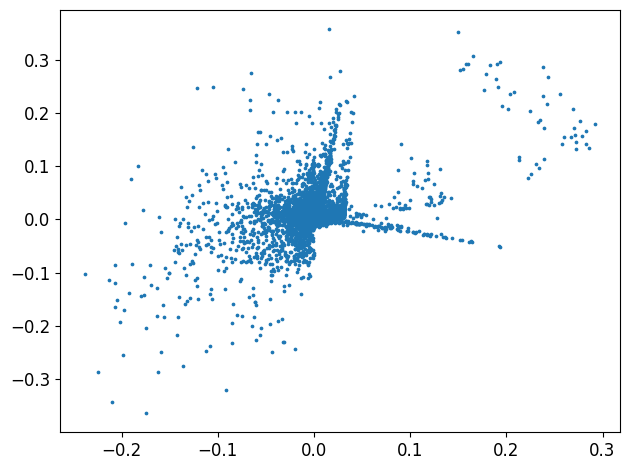

In [ ]:
scprep.plot.scatter2d(z_pred)

In [ ]:
np.save('ae_embedding_recon_only.npy', z_pred)